In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
# Import needed libraries
import tensorflow as tf
print('TensorFlow version:', tf.__version__)

import keras
print('Keras version:', keras.__version__)

# Matlab plotting
import matplotlib
import matplotlib.pyplot as plt
#mpl.rcParams['figure.figsize'] = (8, 6)
#mpl.rcParams['axes.grid'] = False

# Helper libraries
import os
import sys
import time
import datetime

import numpy as np
import pandas as pd
import sklearn
from   sklearn.model_selection import train_test_split

import IPython
import IPython.display
import seaborn as sns

TensorFlow version: 2.20.0
Keras version: 3.13.2


In [5]:
from pathlib import Path

IMAGES_PATH = Path() / "images" / "rnn"
IMAGES_PATH.mkdir(parents=True, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=300):
    path = IMAGES_PATH / f"{fig_id}.{fig_extension}"
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

In [6]:
# Test for GPU and determine what GPU we have
import platform
import subprocess
gpu_devices = tf.config.list_physical_devices('GPU')

gpu_name = tf.test.gpu_device_name()
if gpu_name != '':
    print('TF-GPU-devname:',tf.test.gpu_device_name())
    sys_details = tf.sysconfig.get_build_info()
    physical_devices = tf.config.list_physical_devices('GPU')
    print("Num GPUs:", len(physical_devices))
    if platform.system() == "Darwin":
        print('GPU on Mac!')
    else:
        cuda_version = sys_details["cuda_version"]
        print('TF-cuda version:',cuda_version)
        if len(physical_devices)>0:
            process = subprocess.Popen(['nvidia-smi','-L'], stdout=subprocess.PIPE, stderr=subprocess.PIPE)
            print(process.communicate())
        # If possible to run code with 16 bits float instead of 32 bits float, this code activates such functionality:
        if gpu_devices:
            details = tf.config.experimental.get_device_details(gpu_devices[0])
            compute_capability=details.get('compute_capability')
            print("Compute capability:",compute_capability)
            if compute_capability[0]>6:
                print("Turning on mixed_float16")
                policy = keras.mixed_precision.Policy('mixed_float16')
                keras.mixed_precision.set_global_policy(policy)
else:
    print('TF-device CPU')

TF-GPU-devname: /device:GPU:0
Num GPUs: 2
TF-cuda version: 12.5.1
(b'GPU 0: Tesla T4 (UUID: GPU-50e0f4b0-89b9-537d-c358-3c2afacb9af8)\nGPU 1: Tesla T4 (UUID: GPU-6821194a-e19e-ecc2-4fda-162b9793ddf8)\n', b'')
Compute capability: (7, 5)
Turning on mixed_float16


I0000 00:00:1790858050.354191      58 gpu_device.cc:2020] Created device /device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790858050.357011      58 gpu_device.cc:2020] Created device /device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1790858050.372464      58 gpu_device.cc:2020] Created device /device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790858050.374032      58 gpu_device.cc:2020] Created device /device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [7]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


> # Step 1
Load Data

In [8]:
!kaggle datasets download -d robikscube/hourly-energy-consumption

!unzip -o hourly-energy-consumption.zip -d pjm_data

Dataset URL: https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption
License(s): CC0-1.0
100%|██████████████████████████████████████| 11.4M/11.4M [00:00<00:00, 90.6MB/s]

Archive:  hourly-energy-consumption.zip
  inflating: pjm_data/AEP_hourly.csv  
  inflating: pjm_data/COMED_hourly.csv  
  inflating: pjm_data/DAYTON_hourly.csv  
  inflating: pjm_data/DEOK_hourly.csv  
  inflating: pjm_data/DOM_hourly.csv  
  inflating: pjm_data/DUQ_hourly.csv  
  inflating: pjm_data/EKPC_hourly.csv  
  inflating: pjm_data/FE_hourly.csv  
  inflating: pjm_data/NI_hourly.csv  
  inflating: pjm_data/PJME_hourly.csv  
  inflating: pjm_data/PJMW_hourly.csv  
  inflating: pjm_data/PJM_Load_hourly.csv  
  inflating: pjm_data/est_hourly.paruqet  
  inflating: pjm_data/pjm_hourly_est.csv  


In [9]:
!pip install statsmodels
!pip install xgboost
!pip install tensorflow

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error


In [11]:
# Phase 1: Data Understanding

import pandas as pd

pjm_df = pd.read_csv(
    "pjm_data/PJME_hourly.csv",
     parse_dates=["Datetime"]
)

print("Shape:\n", pjm_df.shape)
print("Head:\n", pjm_df.head())
print("Index:\n", pjm_df.index) # If you see RangeIndex instead of DatetimeIndex() you will have an error splitting the data into train, val and test datasets
print("DTypes:\n", pjm_df.dtypes)

pjm_df.info()

pjm_df.describe()

Shape:
 (145366, 2)
Head:
              Datetime  PJME_MW
0 2002-12-31 01:00:00  26498.0
1 2002-12-31 02:00:00  25147.0
2 2002-12-31 03:00:00  24574.0
3 2002-12-31 04:00:00  24393.0
4 2002-12-31 05:00:00  24860.0
Index:
 RangeIndex(start=0, stop=145366, step=1)
DTypes:
 Datetime    datetime64[ns]
PJME_MW            float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  145366 non-null  datetime64[ns]
 1   PJME_MW   145366 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 2.2 MB


,Datetime,PJME_MW
count,145366,145366.000000
mean,2010-04-18 03:25:25.999202048,32080.222831
min,2002-01-01 01:00:00,14544.000000
25%,2006-02-23 14:15:00,27573.000000
50%,2010-04-18 04:30:00,31421.000000
75%,2014-06-10 18:45:00,35650.000000
max,2018-08-03 00:00:00,62009.000000
std,NaN,6464.012166


In [12]:
#df = pd.read_csv("/kaggle/input/hourly-energy-consumption/PJME_hourly.csv")


In [13]:
#df.head()

#df.info()

#df.describe()

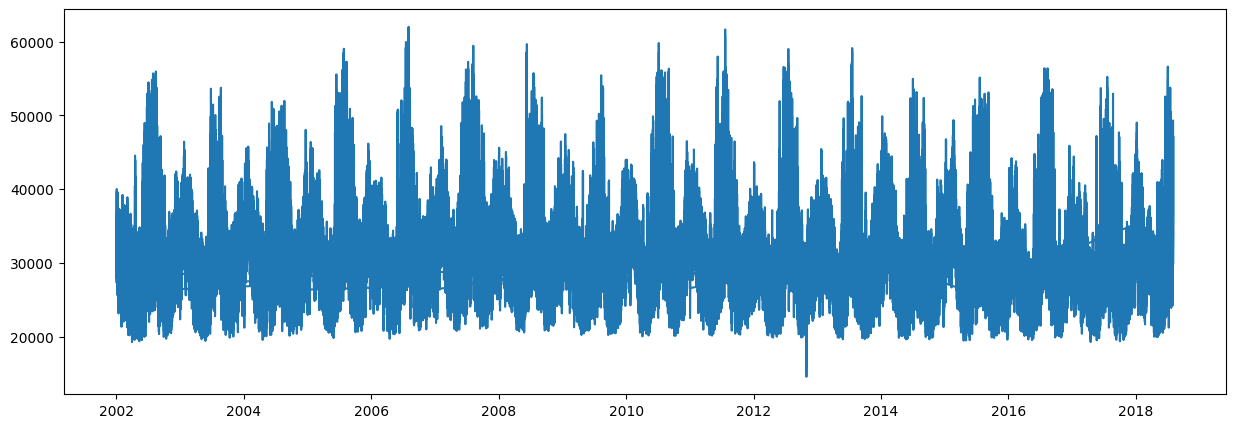

In [14]:
plt.figure(figsize=(15,5))

plt.plot(pjm_df["Datetime"], pjm_df["PJME_MW"])
plt.show()

#What to Look For: Daily cycles, Weekly cycles, Yearly cycles, Outliers

> # Step 2
Convert Datetime

In [15]:
pjm_df["Datetime"] = pd.to_datetime(pjm_df["Datetime"])

pjm_df = pjm_df.sort_values("Datetime")


> # Step 3
Set Datetime Index

In [16]:
# This will help with splitting the dataset
pjm_df = pjm_df.set_index("Datetime") # This will help with splitting the dataset

In [17]:
print(pjm_df.index)

DatetimeIndex(['2002-01-01 01:00:00', '2002-01-01 02:00:00',
               '2002-01-01 03:00:00', '2002-01-01 04:00:00',
               '2002-01-01 05:00:00', '2002-01-01 06:00:00',
               '2002-01-01 07:00:00', '2002-01-01 08:00:00',
               '2002-01-01 09:00:00', '2002-01-01 10:00:00',
               ...
               '2018-08-02 15:00:00', '2018-08-02 16:00:00',
               '2018-08-02 17:00:00', '2018-08-02 18:00:00',
               '2018-08-02 19:00:00', '2018-08-02 20:00:00',
               '2018-08-02 21:00:00', '2018-08-02 22:00:00',
               '2018-08-02 23:00:00', '2018-08-03 00:00:00'],
              dtype='datetime64[ns]', name='Datetime', length=145366, freq=None)


In [18]:
print(pjm_df.index.min())
print(pjm_df.index.max())

2002-01-01 01:00:00
2018-08-03 00:00:00


> Step 4: EDA Checklist:
> 1. Missing values
2. Data range
3. Trends
4. Daily seasonality
5. Weekly seasonality
6. Monthly seasonality
7. Yearly seasonality
8. Outliers
`

> CLEANING

In [19]:
#Missing Values
pjm_df.isnull().sum()

PJME_MW    0
dtype: int64

In [20]:
pjm_df.isna().any()

PJME_MW    False
dtype: bool

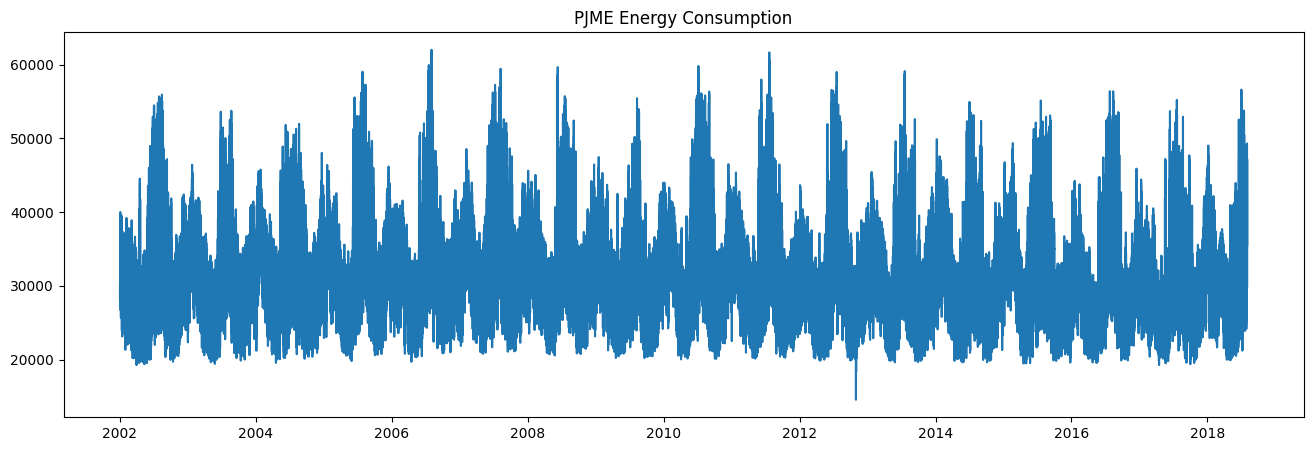

In [21]:
#Plot Entire Time Series
import matplotlib.pyplot as plt

plt.figure(figsize=(16,5))

plt.plot(pjm_df.index, pjm_df["PJME_MW"])

plt.title("PJME Energy Consumption")

plt.show()

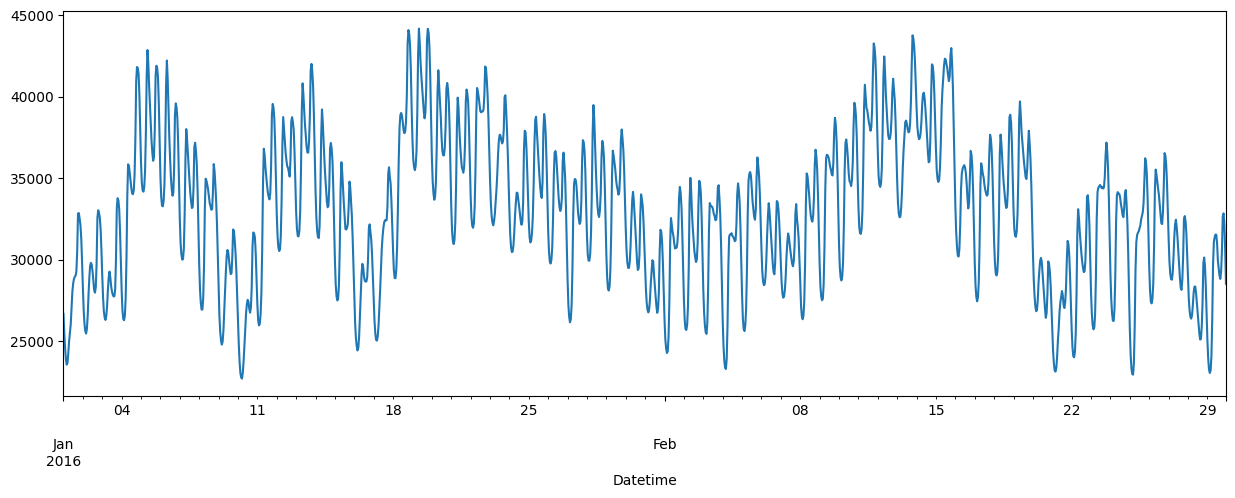

In [22]:
# Check Two Months
pjm_df.loc["2016-01":"2016-02"]["PJME_MW"].plot(
    figsize=(15,5)
)

plt.show()

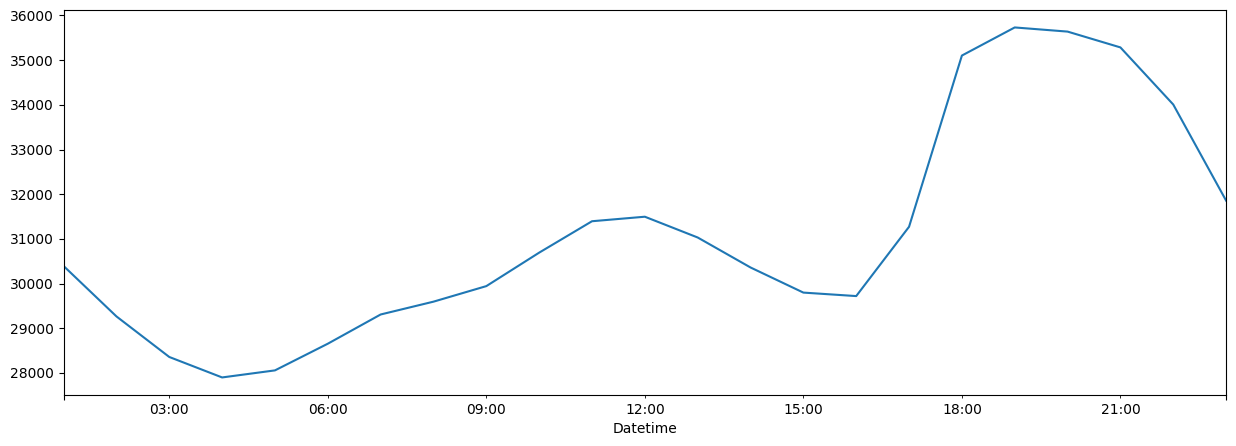

In [23]:
# Check jan Month
pjm_df.loc["2002-01-01 01:00:00":"2002-01-01 23:00:00"]["PJME_MW"].plot(
    figsize=(15,5)
)

plt.show()

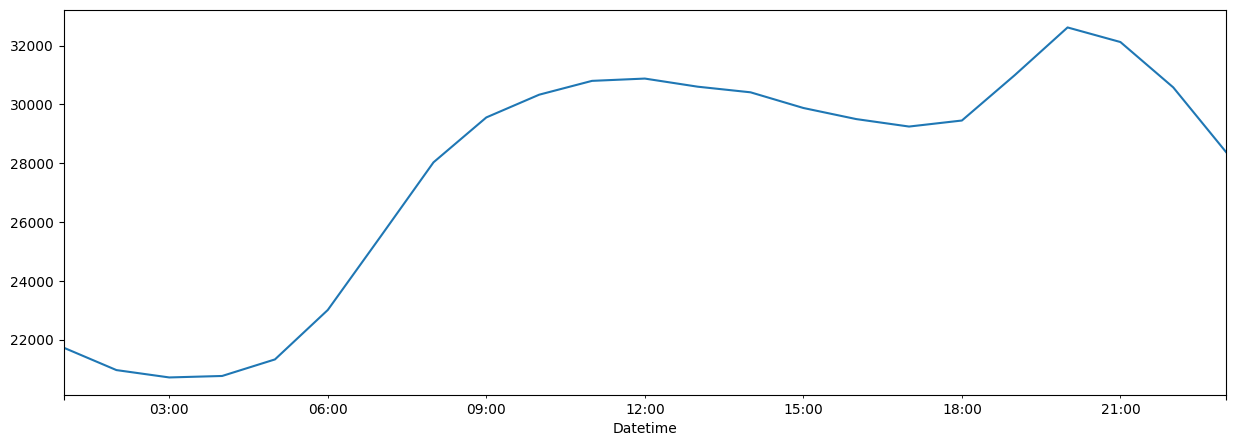

In [24]:
# Check April Month
pjm_df.loc["2002-04-01 01:00:00":"2002-04-01 23:00:00"]["PJME_MW"].plot(
    figsize=(15,5)
)

plt.show()

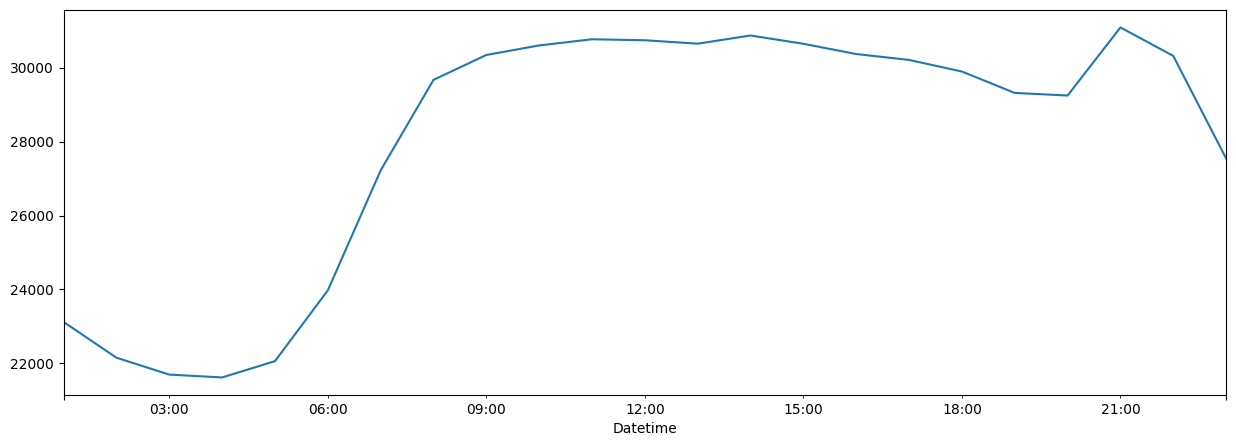

In [25]:
#Check may Month
pjm_df.loc["2002-05-01 01:00:00":"2002-05-01 23:00:00"]["PJME_MW"].plot(
    figsize=(15,5)
)

plt.show()

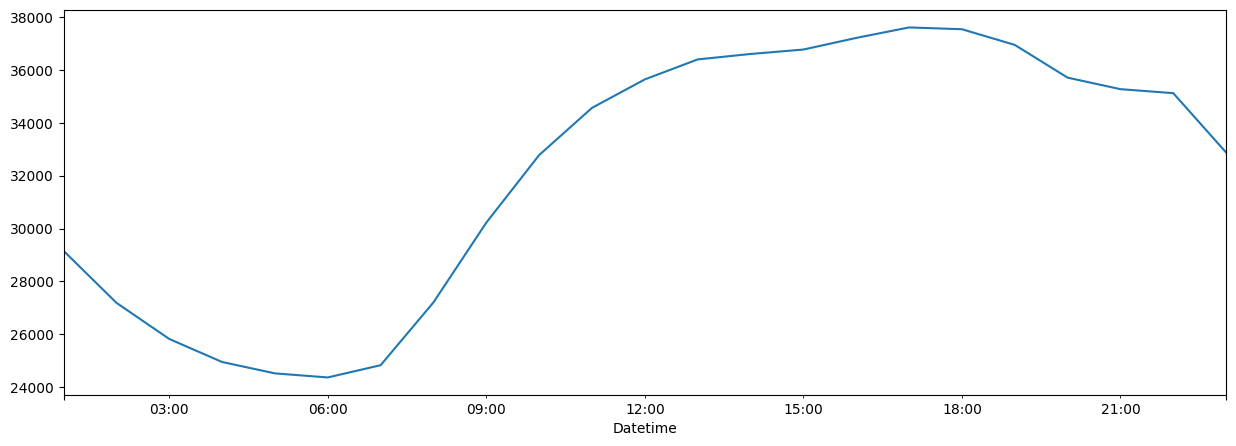

In [26]:
# Check june Month
pjm_df.loc["2002-06-01 01:00:00":"2002-06-01 23:00:00"]["PJME_MW"].plot(
    figsize=(15,5)
)

plt.show()

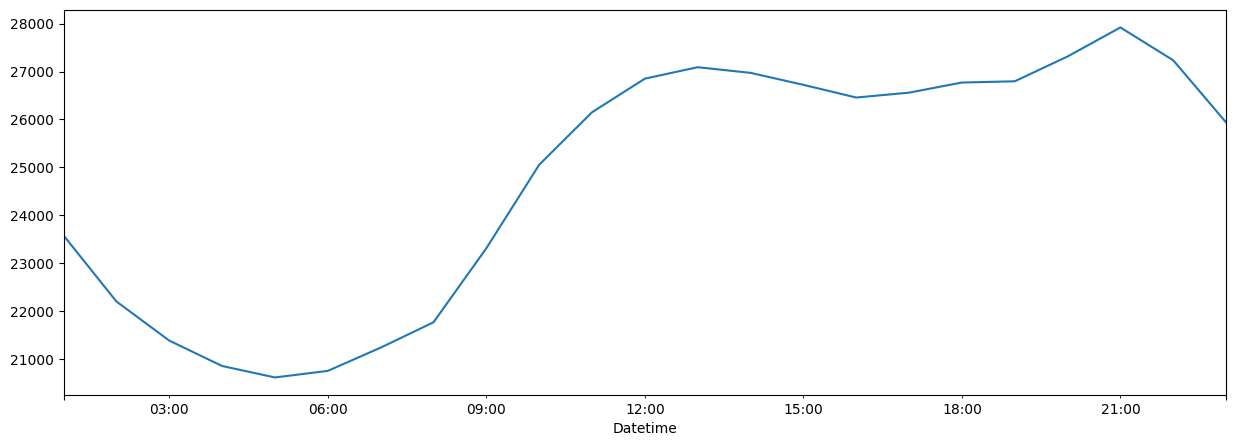

In [27]:
# Check sept Month
pjm_df.loc["2002-09-01 01:00:00":"2002-09-01 23:00:00"]["PJME_MW"].plot(
    figsize=(15,5)
)

plt.show()

> Create Time Features

In [28]:
#Create Time Features
pjm_df["hour"] = pjm_df.index.hour

pjm_df["dayofweek"] = pjm_df.index.dayofweek

pjm_df["month"] = pjm_df.index.month

pjm_df["year"] = pjm_df.index.year

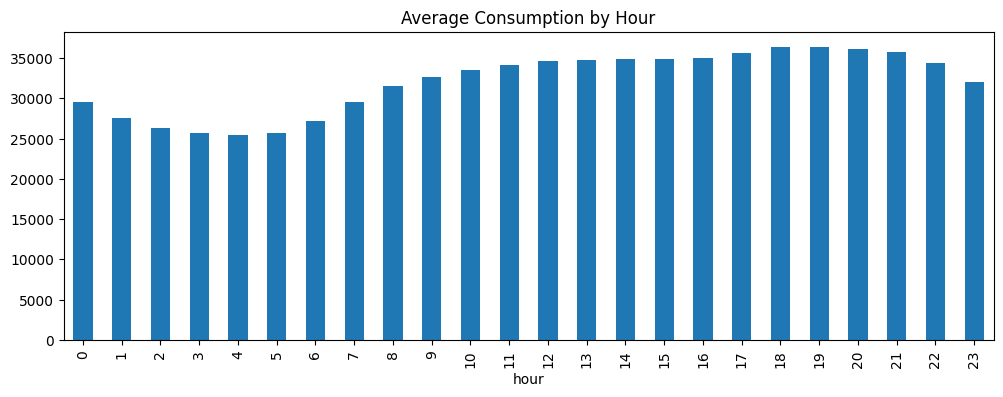

In [29]:
#Hourly Seasonality
hourly_profile = pjm_df.groupby(
    "hour"
)["PJME_MW"].mean()

hourly_profile.plot(
    kind="bar",
    figsize=(12,4)
)

plt.title("Average Consumption by Hour")
plt.show()

> When is demand highest? At 18.00 or between 12.00 and 23.00

> When is demand lowest? Between 2 and 5 am

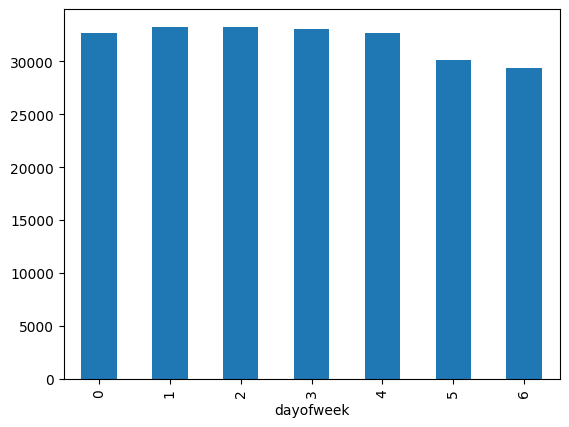

In [30]:
# Weekly Seasonality
#Weekdays > Weekends

weekly_profile = pjm_df.groupby(
    "dayofweek"
)["PJME_MW"].mean()

weekly_profile.plot(
    kind="bar"
)

plt.show()

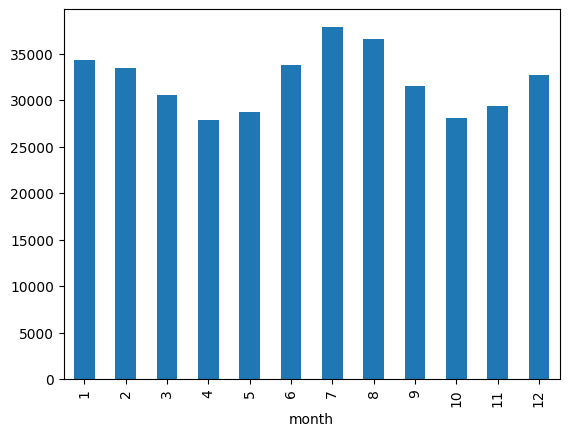

In [31]:
#Monthly Seasonality
monthly_profile = pjm_df.groupby(
    "month"
)["PJME_MW"].mean()

monthly_profile.plot(
    kind="bar"
)

plt.show()


> Summer demand? Consumption goes up from May and peaks at july and aug and then comes down to october.

> Winter demand?Consumption goes up from october and comes down around march, april. 

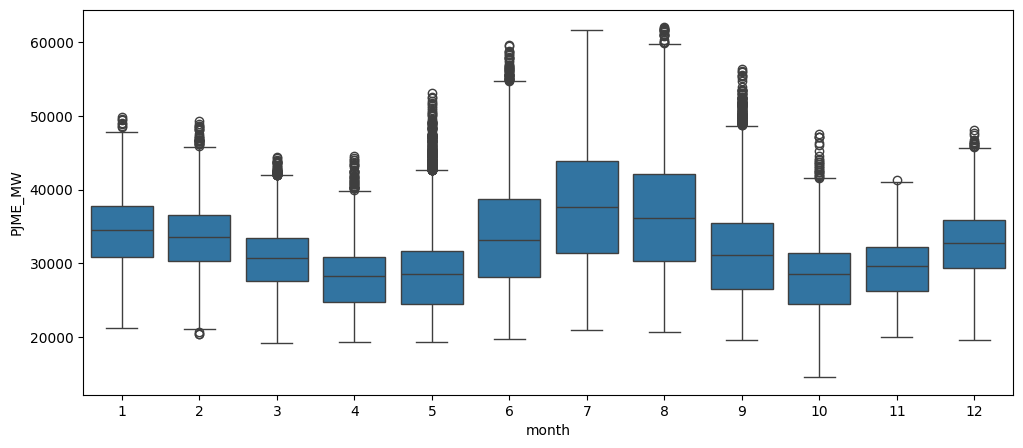

In [32]:
# Boxplot by Month
import seaborn as sns

plt.figure(figsize=(12,5))

sns.boxplot(
    x="month",
    y="PJME_MW",
    data=pjm_df
)

plt.show()

# Shows: Median, Spread, Outliers

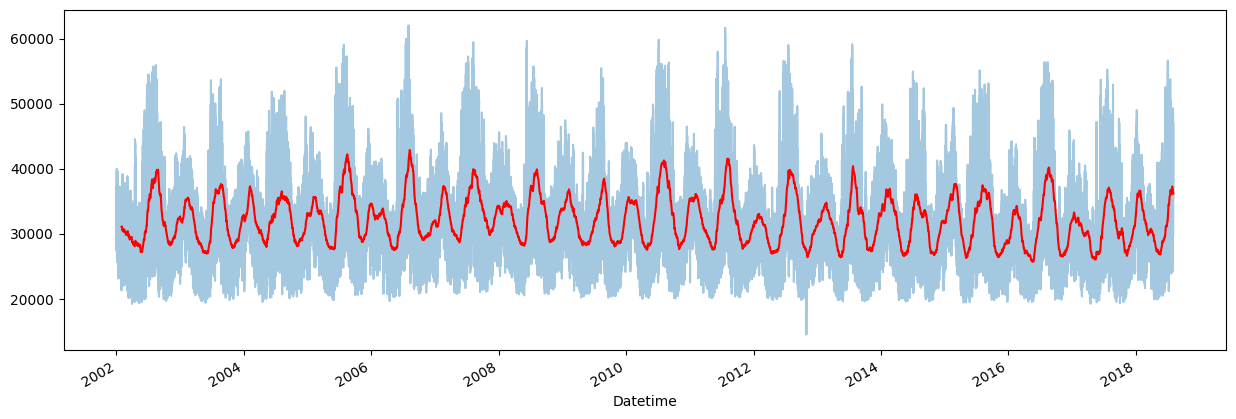

In [33]:
# Rolling Mean
pjm_df["PJME_MW"].plot(
    figsize=(15,5),
    alpha=0.4
)

pjm_df["PJME_MW"].rolling(
    24*30
).mean().plot(
    color="red"  # monthly moving average.
)

plt.show()


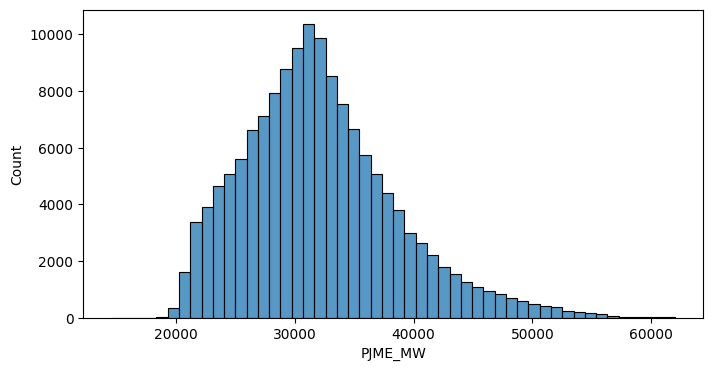

In [34]:
# Distribution
plt.figure(figsize=(8,4))

sns.histplot(
    pjm_df["PJME_MW"],
    bins=50
)

plt.show()

In [35]:
# Outliers
pjm_df.nlargest(
    10,
    "PJME_MW"
)

,PJME_MW,hour,dayofweek,month,year
Datetime,,,,,
2006-08-02 17:00:00,62009.0,17,2,8,2006
2006-08-02 16:00:00,61909.0,16,2,8,2006
2006-08-03 17:00:00,61796.0,17,3,8,2006
2006-08-03 16:00:00,61770.0,16,3,8,2006
2011-07-22 15:00:00,61646.0,15,4,7,2011
2006-08-01 17:00:00,61643.0,17,1,8,2006
2006-08-02 15:00:00,61641.0,15,2,8,2006
2006-08-02 18:00:00,61610.0,18,2,8,2006
2011-07-22 16:00:00,61608.0,16,4,7,2011


> Heat wave? 

> Storm?

> Data error?


In [36]:
# Correlation of Lags

pjm_df["lag_24"] = pjm_df["PJME_MW"].shift(24) # 24 hour correlation

pjm_df["lag_168"] = pjm_df["PJME_MW"].shift(168) # 7 day correlation

pjm_df[
    ["PJME_MW",
     "lag_24",
     "lag_168"]
].corr()
# This will later help justify XGBoost.

,PJME_MW,lag_24,lag_168
PJME_MW,1.000000,0.891387,0.781848
lag_24,0.891387,1.000000,0.744243
lag_168,0.781848,0.744243,1.000000


In [37]:
pjm_df.head()

,PJME_MW,hour,dayofweek,month,year,lag_24,lag_168
Datetime,,,,,,,
2002-01-01 01:00:00,30393.0,1,1,1,2002,NaN,NaN
2002-01-01 02:00:00,29265.0,2,1,1,2002,NaN,NaN
2002-01-01 03:00:00,28357.0,3,1,1,2002,NaN,NaN
2002-01-01 04:00:00,27899.0,4,1,1,2002,NaN,NaN
2002-01-01 05:00:00,28057.0,5,1,1,2002,NaN,NaN


> # Step 5
Train / Validation / Test Split

In [38]:
#Train/Test Split
split_date = "2017-01-01"

train = pjm_df[pjm_df.index < '2016-01-01'].copy()

val = pjm_df[
    (pjm_df.index >= '2016-01-01') &
    (pjm_df.index < '2017-01-01')
].copy()

test = pjm_df[pjm_df.index >= '2017-01-01'].copy()

In [39]:
print(train.shape)

print(val.shape)

print(test.shape)

(122686, 7)
(8784, 7)
(13896, 7)


# Step 6
Naive Forecast

In [40]:
test.head()

,PJME_MW,hour,dayofweek,month,year,lag_24,lag_168
Datetime,,,,,,,
2017-01-01 00:00:00,28171.0,0,6,1,2017,31172.0,27565.0
2017-01-01 01:00:00,26879.0,1,6,1,2017,29627.0,26123.0
2017-01-01 02:00:00,25848.0,2,6,1,2017,28744.0,25098.0
2017-01-01 03:00:00,25039.0,3,6,1,2017,28274.0,24594.0
2017-01-01 04:00:00,24637.0,4,6,1,2017,28162.0,24499.0


> There are several NAN values in the prediction column. We need to get rid of them before we continue

In [41]:
# Naive Forecast: Every forecasting project needs a baseline.
test = test.copy()
test.loc[:, "24HR_prediction"] = train["PJME_MW"].iloc[-1]

In [42]:
#Seasonal Daily Naive:
test.loc[:, "24HR_prediction"] = test["PJME_MW"].shift(24)

In [43]:
test.head()

,PJME_MW,hour,dayofweek,month,year,lag_24,lag_168,24HR_prediction
Datetime,,,,,,,,
2017-01-01 00:00:00,28171.0,0,6,1,2017,31172.0,27565.0,NaN
2017-01-01 01:00:00,26879.0,1,6,1,2017,29627.0,26123.0,NaN
2017-01-01 02:00:00,25848.0,2,6,1,2017,28744.0,25098.0,NaN
2017-01-01 03:00:00,25039.0,3,6,1,2017,28274.0,24594.0,NaN
2017-01-01 04:00:00,24637.0,4,6,1,2017,28162.0,24499.0,NaN


In [44]:
test["PJME_MW"]

Datetime
2017-01-01 00:00:00    28171.0
2017-01-01 01:00:00    26879.0
2017-01-01 02:00:00    25848.0
2017-01-01 03:00:00    25039.0
2017-01-01 04:00:00    24637.0
                        ...   
2018-08-02 20:00:00    44057.0
2018-08-02 21:00:00    43256.0
2018-08-02 22:00:00    41552.0
2018-08-02 23:00:00    38500.0
2018-08-03 00:00:00    35486.0
Name: PJME_MW, Length: 13896, dtype: float64

In [45]:
test["24HR_prediction"]

Datetime
2017-01-01 00:00:00        NaN
2017-01-01 01:00:00        NaN
2017-01-01 02:00:00        NaN
2017-01-01 03:00:00        NaN
2017-01-01 04:00:00        NaN
                        ...   
2018-08-02 20:00:00    46912.0
2018-08-02 21:00:00    45985.0
2018-08-02 22:00:00    44094.0
2018-08-02 23:00:00    40666.0
2018-08-03 00:00:00    37158.0
Name: 24HR_prediction, Length: 13896, dtype: float64

In [46]:
#Creating a new df without NAN values.
comparison = test[
    ["PJME_MW", "24HR_prediction"]
].dropna()


print(comparison.shape)

(13872, 2)


In [47]:
#Evaluate
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

naive_mae_24 = mean_absolute_error(
    comparison["PJME_MW"],
    comparison["24HR_prediction"]
)

naive_rmse_24 = np.sqrt(
    mean_squared_error(
        comparison["PJME_MW"],
        comparison["24HR_prediction"]
    )
)

print("MAE_Daily:", naive_mae_24)
print("RMSE_Daily:", naive_rmse_24)

MAE_Daily: 2298.1572952710494
RMSE_Daily: 3132.783186437223


> The Naive daily MAE is 2298.15 and RMSE is 3132 .78

In [48]:
# pjm_df["naive_168"] = pjm_df["PJME_MW"].shift(168)

In [49]:
# Previous week
# test.loc[:, "prediction"] = test["PJME_MW"].shift(168)

> # Step 7

# ARIMA

In [50]:
print(train.index.duplicated().sum())

2


In [51]:
train = train[~train.index.duplicated(keep='first')]

In [52]:
train.head

<bound method NDFrame.head of                      PJME_MW  hour  dayofweek  month  year   lag_24  lag_168
Datetime                                                                    
2002-01-01 01:00:00  30393.0     1          1      1  2002      NaN      NaN
2002-01-01 02:00:00  29265.0     2          1      1  2002      NaN      NaN
2002-01-01 03:00:00  28357.0     3          1      1  2002      NaN      NaN
2002-01-01 04:00:00  27899.0     4          1      1  2002      NaN      NaN
2002-01-01 05:00:00  28057.0     5          1      1  2002      NaN      NaN
...                      ...   ...        ...    ...   ...      ...      ...
2015-12-31 19:00:00  32732.0    19          3     12  2015  33477.0  29989.0
2015-12-31 20:00:00  31564.0    20          3     12  2015  32674.0  28833.0
2015-12-31 21:00:00  30404.0    21          3     12  2015  31800.0  28070.0
2015-12-31 22:00:00  29210.0    22          3     12  2015  30323.0  27328.0
2015-12-31 23:00:00  27944.0    23          3 

In [53]:
print(train.index.duplicated().sum()) # Now we have no duplicates

0


In [54]:
print(train.index.is_monotonic_increasing) # Shows that the timeseries is proprly ordered

True


In [55]:
print("Duplicates:", train.index.duplicated().sum())

print("Sorted:", train.index.is_monotonic_increasing)

Duplicates: 0
Sorted: True


In [56]:
train_series = train["PJME_MW"]

print(train_series.index.inferred_freq)

None


In [57]:
# Phase 4: ARIMA: Classical statistical forecasting.
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(
    train["PJME_MW"].asfreq("h"),
    order=(5,1,0)
)

model_fit = model.fit()

In [58]:
forecast = model_fit.forecast(
    steps=len(test)
)

In [59]:
comparison_arima = comparison.copy()

print(comparison_arima.head)


<bound method NDFrame.head of                      PJME_MW  24HR_prediction
Datetime                                     
2017-01-02 00:00:00  27617.0          28171.0
2017-01-02 01:00:00  26216.0          26879.0
2017-01-02 02:00:00  25381.0          25848.0
2017-01-02 03:00:00  24962.0          25039.0
2017-01-02 04:00:00  24873.0          24637.0
...                      ...              ...
2018-08-02 20:00:00  44057.0          46912.0
2018-08-02 21:00:00  43256.0          45985.0
2018-08-02 22:00:00  41552.0          44094.0
2018-08-02 23:00:00  38500.0          40666.0
2018-08-03 00:00:00  35486.0          37158.0

[13872 rows x 2 columns]>


In [60]:
comparison_arima["ARIMA_forecast"] = (forecast[:len(comparison_arima)].values)

In [61]:
comparison_arima["ARIMA_forecast"].head

<bound method NDFrame.head of Datetime
2017-01-02 00:00:00    26922.581742
2017-01-02 01:00:00    26364.939894
2017-01-02 02:00:00    26203.429617
2017-01-02 03:00:00    26306.101192
2017-01-02 04:00:00    26611.916705
                           ...     
2018-08-02 20:00:00    27872.896210
2018-08-02 21:00:00    27872.896210
2018-08-02 22:00:00    27872.896210
2018-08-02 23:00:00    27872.896210
2018-08-03 00:00:00    27872.896210
Name: ARIMA_forecast, Length: 13872, dtype: float64>

In [62]:
comparison_arima["ARIMA_forecast"].shape

(13872,)

In [63]:
print(comparison_arima.isna().sum()) # Result should be 0 for all columns

PJME_MW            0
24HR_prediction    0
ARIMA_forecast     0
dtype: int64


In [64]:
comparison_arima.head()

,PJME_MW,24HR_prediction,ARIMA_forecast
Datetime,,,
2017-01-02 00:00:00,27617.0,28171.0,26922.581742
2017-01-02 01:00:00,26216.0,26879.0,26364.939894
2017-01-02 02:00:00,25381.0,25848.0,26203.429617
2017-01-02 03:00:00,24962.0,25039.0,26306.101192
2017-01-02 04:00:00,24873.0,24637.0,26611.916705


In [65]:
mae_ARIMA = mean_absolute_error(
    comparison_arima["PJME_MW"],  # We are using comparison dataset so that we can compare with Naive_24
    comparison_arima["ARIMA_forecast"]
)

rmse_ARIMA = np.sqrt(
    mean_squared_error(
        comparison_arima["PJME_MW"],
        comparison_arima["ARIMA_forecast"]
    )
)

print("ARIMA mae:", mae_ARIMA)
print("ARIMA rmse:", rmse_ARIMA)

ARIMA mae: 5137.585767972361
ARIMA rmse: 6913.427909720877


In [66]:
results = pd.DataFrame({
    "Model": ["Naive_24", "ARIMA"],
    "MAE": [naive_mae_24, mae_ARIMA],
    "RMSE": [naive_rmse_24, rmse_ARIMA]
})

print(results)

      Model          MAE         RMSE
0  Naive_24  2298.157295  3132.783186
1     ARIMA  5137.585768  6913.427910


> The ARIMA mae and rsme are worse than our hour Naive_24 baseline. So lets look at
> another model SARIMAX

> # SARIMAX Model 

In [67]:
series = train["PJME_MW"].asfreq("h")

missing_times = series[series.isna()]

print(missing_times.head(50))
# If you get results like this 03:00:00 and 02:00:00 this is daylight saving time.
# Datetime
# 2002-04-07 03:00:00   NaN
# 2002-10-27 02:00:00   NaN
# 2003-04-06 03:00:00   NaN
# 2003-10-26 02:00:00   NaN

Datetime
2002-04-07 03:00:00   NaN
2002-10-27 02:00:00   NaN
2003-04-06 03:00:00   NaN
2003-10-26 02:00:00   NaN
2004-04-04 03:00:00   NaN
2004-10-31 02:00:00   NaN
2005-04-03 03:00:00   NaN
2005-10-30 02:00:00   NaN
2006-04-02 03:00:00   NaN
2006-10-29 02:00:00   NaN
2007-03-11 03:00:00   NaN
2007-11-04 02:00:00   NaN
2008-03-09 03:00:00   NaN
2008-11-02 02:00:00   NaN
2009-03-08 03:00:00   NaN
2009-11-01 02:00:00   NaN
2010-03-14 03:00:00   NaN
2010-11-07 02:00:00   NaN
2010-12-10 00:00:00   NaN
2011-03-13 03:00:00   NaN
2011-11-06 02:00:00   NaN
2012-03-11 03:00:00   NaN
2012-11-04 02:00:00   NaN
2013-03-10 03:00:00   NaN
2013-11-03 02:00:00   NaN
2014-03-09 03:00:00   NaN
2015-03-08 03:00:00   NaN
Name: PJME_MW, dtype: float64


In [68]:
train_hourly = (
    train["PJME_MW"]
        .asfreq("h")
        .interpolate(method="time")
)

print(train_hourly.isna().sum())
print(train_hourly.index.freq) # results 0 <Hour> which now means the Sarimax input is cleaner

0
<Hour>


In [69]:
len(train_hourly) # Will tell us if we are hitting a dataset-size problem
# over 100,000 hours will lead to memory exploding


122711

> Data Quality Observation

The PJME time series did not have a regular hourly frequency.

A check using:

    train.index.inferred_freq

returned None.

Converting the series using:

    asfreq("h")

revealed 27 missing hourly timestamps.

These missing observations were interpolated before fitting the SARIMAX model to ensure a continuous hourly time series.

In [70]:
len(train)

122684

In [71]:
print(len(test)) # These train and test sets are too large and will slow the kernel 
# down when the Sarimax model runs

13896


In [72]:
#"During EDA I discovered 27 missing hourly observations caused by timestamp irregularities. These were investigated and handled before fitting SARIMAX."
# The SARIMAX is running on many years of hourly data and this will shut your kernel down.
# Instea, we are going to train the model on a much smaller data set.

train_hourly = (
    train["PJME_MW"]
    .asfreq("h")
    .interpolate(method="time")  # This handles the 27 Daylight Saving time (DST) transitions
)

train_small = train_hourly[-24*365:]

In [73]:
len(train_small)

8760

In [74]:
train_small = train_hourly[-24*365-24*30:-24*30]  # These create smaller train and test sets
test_small  = train_hourly[-24*30:]

print(len(train_small))
print(len(test_small))

test_small.head

8760
720


<bound method NDFrame.head of Datetime
2015-12-02 00:00:00    26091.0
2015-12-02 01:00:00    24389.0
2015-12-02 02:00:00    23401.0
2015-12-02 03:00:00    22911.0
2015-12-02 04:00:00    22826.0
                        ...   
2015-12-31 19:00:00    32732.0
2015-12-31 20:00:00    31564.0
2015-12-31 21:00:00    30404.0
2015-12-31 22:00:00    29210.0
2015-12-31 23:00:00    27944.0
Freq: h, Name: PJME_MW, Length: 720, dtype: float64>

In [75]:
type(test_small)

pandas.core.series.Series

In [76]:
test_small.head()

Datetime
2015-12-02 00:00:00    26091.0
2015-12-02 01:00:00    24389.0
2015-12-02 02:00:00    23401.0
2015-12-02 03:00:00    22911.0
2015-12-02 04:00:00    22826.0
Freq: h, Name: PJME_MW, dtype: float64

In [77]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
#"During EDA I discovered 27 missing hourly observations caused by timestamp irregularities. These were investigated and handled before fitting SARIMAX."
# The SARIMAX is running on many years of hourly data and this will shut your kernel down.
# Instea, we are going to train the model on a much smaller data set.

model = SARIMAX(
    train_small, 
    order=(1,1,0),
    seasonal_order=(0,1,1,24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

# model_fit = model.fit()
sarimax_fit = model.fit(
    disp=False,
    maxiter=50
)

> order=(1,1,0)

p = 1   autoregressive term
d = 1   first differencing
q = 0   no moving average term

> seasonal_order=(0,1,1,24)

P = 0
D = 1
Q = 1
s = 24 hours

In [78]:
sarimax_forecast = sarimax_fit.forecast(
    steps=len(test_small)
)

In [79]:
print(len(sarimax_forecast))
print(len(test_small)) # These must match in size

720
720


In [80]:
from sklearn.metrics import mean_absolute_error

sarimax_mae = mean_absolute_error(
    test_small,
    sarimax_forecast
)

print(f"SARIMAX MAE: {sarimax_mae:.2f}")

SARIMAX MAE: 4490.13


In [81]:
from sklearn.metrics import root_mean_squared_error

sarimax_rmse = root_mean_squared_error(
    test_small,
    sarimax_forecast
)

print(f"SARIMAX RMSE: {sarimax_rmse:.2f}")

SARIMAX RMSE: 5073.74


**VAlidation plot**

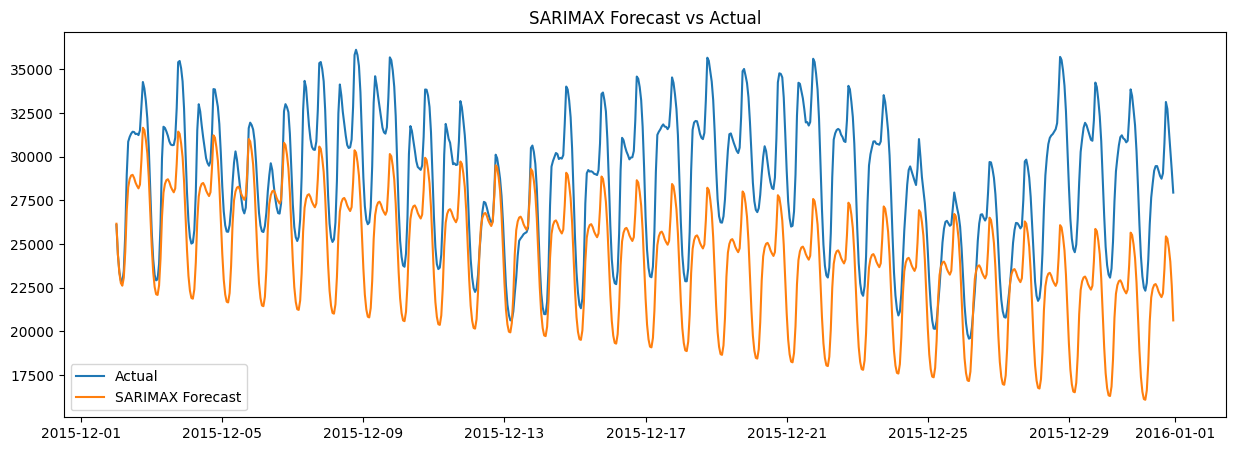

In [82]:
plt.figure(figsize=(15,5))

plt.plot(
    test_small.index,
    test_small,
    label="Actual"
)

plt.plot(
    test_small.index,
    sarimax_forecast,
    label="SARIMAX Forecast"
)

plt.title("SARIMAX Forecast vs Actual")
plt.legend()
plt.show()

> # Step 8

# XGBoost# 

In [83]:
pjm_df = pd.read_csv(
    "pjm_data/PJME_hourly.csv",
     parse_dates=["Datetime"]
)

print("Shape:\n", pjm_df.shape)
print("Head:\n", pjm_df.head())
print("Index:\n", pjm_df.index) # If you see RangeIndex instead of DatetimeIndex() you will have an error splitting the data into train, val and test datasets
print("DTypes:\n", pjm_df.dtypes)

pjm_df.info()

pjm_df.describe()

Shape:
 (145366, 2)
Head:
              Datetime  PJME_MW
0 2002-12-31 01:00:00  26498.0
1 2002-12-31 02:00:00  25147.0
2 2002-12-31 03:00:00  24574.0
3 2002-12-31 04:00:00  24393.0
4 2002-12-31 05:00:00  24860.0
Index:
 RangeIndex(start=0, stop=145366, step=1)
DTypes:
 Datetime    datetime64[ns]
PJME_MW            float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145366 entries, 0 to 145365
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  145366 non-null  datetime64[ns]
 1   PJME_MW   145366 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 2.2 MB


,Datetime,PJME_MW
count,145366,145366.000000
mean,2010-04-18 03:25:25.999202048,32080.222831
min,2002-01-01 01:00:00,14544.000000
25%,2006-02-23 14:15:00,27573.000000
50%,2010-04-18 04:30:00,31421.000000
75%,2014-06-10 18:45:00,35650.000000
max,2018-08-03 00:00:00,62009.000000
std,NaN,6464.012166


> CLEANING 

In [84]:
# Converting datetime
pjm_df["Datetime"] = pd.to_datetime(pjm_df["Datetime"]) 

pjm_df = pjm_df.sort_values("Datetime")
pjm_df.head

<bound method NDFrame.head of                   Datetime  PJME_MW
8734   2002-01-01 01:00:00  30393.0
8735   2002-01-01 02:00:00  29265.0
8736   2002-01-01 03:00:00  28357.0
8737   2002-01-01 04:00:00  27899.0
8738   2002-01-01 05:00:00  28057.0
...                    ...      ...
140250 2018-08-02 20:00:00  44057.0
140251 2018-08-02 21:00:00  43256.0
140252 2018-08-02 22:00:00  41552.0
140253 2018-08-02 23:00:00  38500.0
140254 2018-08-03 00:00:00  35486.0

[145366 rows x 2 columns]>

In [85]:
# This will help with splitting the dataset
#Setting Datetime index
pjm_df = pjm_df.set_index("Datetime") # This will help with splitting the dataset
print("Shape:\n", pjm_df.shape)

Shape:
 (145366, 1)


In [86]:
# Lets make a copy of the dataframe

pjm_df_xgb_copy = pjm_df.copy()
pjm_df_xgb_copy.head
print("Shape:\n", pjm_df_xgb_copy.shape)

Shape:
 (145366, 1)


In [87]:
print(pjm_df_xgb_copy.index.duplicated().sum())
print("Shape:\n", pjm_df_xgb_copy.shape)

4
Shape:
 (145366, 1)


In [88]:
print(pjm_df_xgb_copy.index.duplicated().sum())

4


In [89]:
pjm_df_xgb_copy = pjm_df_xgb_copy[
    ~pjm_df_xgb_copy.index.duplicated(keep="first")
]

In [90]:
print(pjm_df_xgb_copy.index.duplicated().sum())
print(pjm_df_xgb_copy.shape)

0
(145362, 1)


In [91]:
print(pjm_df_xgb_copy.index.isna().any())

False


In [92]:
pjm_df_xgb_copy = pjm_df_xgb_copy.dropna()
print(pjm_df_xgb_copy.shape)


(145362, 1)


In [93]:
# Unique timestamps
print(pjm_df_xgb_copy.index.duplicated().sum())

# Missing values
print(pjm_df_xgb_copy.isna().sum().sum())

# Shape
print(pjm_df_xgb_copy.shape)

# Chronological order
print(pjm_df_xgb_copy.index.is_monotonic_increasing)

0
0
(145362, 1)
True


> TRAIN/TEST SPLIT

> Dataset split

In [94]:
# Split first
df = pjm_df_xgb_copy.copy()

n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df.iloc[:train_end]
val = df.iloc[train_end:val_end]
test = df.iloc[val_end:]

print(train.shape)
print(val.shape)
print(test.shape)

(101753, 1)
(21804, 1)
(21805, 1)


> FEATURE ENGINEERING

In [95]:
def create_features(df):

    df = df.copy()

    df["lag_24"] = df["PJME_MW"].shift(24)
    df["lag_48"] = df["PJME_MW"].shift(48)
    df["lag_168"] = df["PJME_MW"].shift(168)

    df["hour"] = df.index.hour
    df["dayofweek"] = df.index.dayofweek
    df["month"] = df.index.month
    df["quarter"] = df.index.quarter

    return df

In [96]:
# Create lag features
train = create_features(train)
val = create_features(val)
test = create_features(test)

In [97]:
# Remove Lag-Induced Nulls
train = train.dropna()
val = val.dropna()
test = test.dropna()

In [98]:
print(train.isna().sum().sum())
print(val.isna().sum().sum())
print(test.isna().sum().sum())

0
0
0


Features and Targets

In [99]:
FEATURES = [
    "lag_24",
    "lag_48",
    "lag_168",
    "hour",
    "dayofweek",
    "month",
    "quarter"
]

TARGET = "PJME_MW"

> Train First XGBoost Baseline

In [100]:
import xgboost as xgb

print(xgb.__version__)

3.2.0


In [101]:
from xgboost import XGBRegressor

#help(XGBRegressor)


In [102]:
xgb_model = XGBRegressor()

print(xgb_model.get_params())

{'objective': 'reg:squarederror', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': None, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': None, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': None, 'n_jobs': None, 'num_parallel_tree': None, 'random_state': None, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}


In [103]:
from xgboost import XGBRegressor
from xgboost.callback import EarlyStopping as early_stopping_rounds

xgb_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    early_stopping_rounds=50,
    random_state=42
)

xgb_model.fit(
    train[FEATURES],
    train[TARGET],
    eval_set=[
        (val[FEATURES], val[TARGET])
    ],
    #eval_metric="mae",
    
    verbose=False
)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=50,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=None, num_parallel_tree=None, ...)

In [104]:
print(xgb_model.best_iteration) # This means early stopping is working. 299 trees used from 1000 trees requested

299


In [105]:
'early_stopping_rounds' in xgb_model.get_params()

True

In [106]:
'eval_metric' in xgb_model.get_params()

True

> VAlidation evaluation

In [107]:
val_pred = xgb_model.predict(
    val[FEATURES]
)

In [108]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

xgb_val_mae = mean_absolute_error(
    val[TARGET],
    val_pred
)

xgb_val_rmse = np.sqrt(
    mean_squared_error(
        val[TARGET],
        val_pred
    )
)

print("Validation XGB_Boost MAE:", xgb_val_mae)
print("Validation XGB_Boost RMSE:", xgb_val_rmse)

Validation XGB_Boost MAE: 1672.179415600735
Validation XGB_Boost RMSE: 2291.0539248011673


In [109]:
print(xgb_model.best_iteration)

299


**Validation Plot**

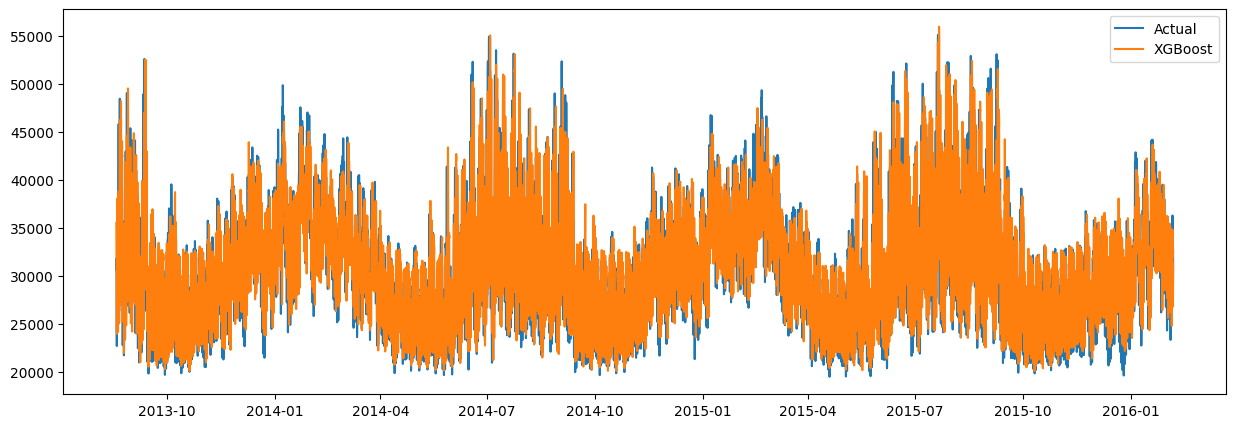

In [110]:
plt.figure(figsize=(15,5))

plt.plot(
    val.index,
    val[TARGET],
    label="Actual"
)

plt.plot(
    val.index,
    val_pred,
    label="XGBoost"
)

plt.legend()
plt.show()

> Validation MAE  = 1672
Validation RMSE = 2291
Best Iteration  = 299. This tells us that the model is not underfitting by stopping too early and not overfitting by using all trees

# #Feature Importance  

In [111]:
import pandas as pd

importance = pd.DataFrame({
    "feature": FEATURES,
    "importance": xgb_model.feature_importances_
})

importance.sort_values(
    "importance",
    ascending=False
)

,feature,importance
0,lag_24,0.602013
2,lag_168,0.151825
1,lag_48,0.095765
4,dayofweek,0.078767
3,hour,0.045566
5,month,0.017424
6,quarter,0.008640


> Although exploratory data analysis suggested monthly seasonality, feature importance analysis from XGBoost showed that daily and weekly lag features carried most of the predictive power. Monthly calendar features contributed relatively little additional information once short-term seasonal patterns were included.

**Save Results**

In [112]:
results = pd.DataFrame({
    "Model": ["XGBoost"],
    "Validation_MAE": [xgb_val_mae],
    "Validation_RMSE": [xgb_val_rmse],
    "Best_Iteration": [xgb_model.best_iteration]
})

results

,Model,Validation_MAE,Validation_RMSE,Best_Iteration
0,XGBoost,1672.179416,2291.053925,299


> Even though the mae and rsme cannot be directly compared to the sarimax which was trained and tested on a smaller dataset, the mae 1672 and rsme 2291 are very good values. 

> Before using Test data let us look at the LSTM model and finally decide which model is best for testing. This prevents data leakage and test set contamination 

> # Step 9
# LSTM

In [113]:
from sklearn.preprocessing import MinMaxScaler

x_scaler = MinMaxScaler()

X_train = x_scaler.fit_transform(train[FEATURES])

X_val = x_scaler.transform(val[FEATURES])

X_test = x_scaler.transform(test[FEATURES])

In [114]:
y_scaler = MinMaxScaler()

y_train = y_scaler.fit_transform(  # the reason we use fit_transform here is to fit the scaler to the training min and max.
    train[[TARGET]]
)

y_val = y_scaler.transform( # subsequest transform functions follow the scale set by the training data
    val[[TARGET]]
)

y_test = y_scaler.transform(
    test[[TARGET]]
)

In [115]:
X_train = X_train.reshape(
    (X_train.shape[0], 1, X_train.shape[1])
)

X_val = X_val.reshape(
    (X_val.shape[0], 1, X_val.shape[1])
)

X_test = X_test.reshape(
    (X_test.shape[0], 1, X_test.shape[1])
)

In [116]:
print(X_train.shape)
print(y_train.shape)

print(X_val.shape)
print(y_val.shape)

print(X_test.shape)
print(y_test.shape)

(101585, 1, 7)
(101585, 1)
(21636, 1, 7)
(21636, 1)
(21637, 1, 7)
(21637, 1)


# LSTM Baseline model

In [117]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

LSTM_model = Sequential()

LSTM_model.add(
    LSTM(
        units=64,
        input_shape=(1, 7)
    )
)

LSTM_model.add(Dropout(0.2))

LSTM_model.add(Dense(32, activation="relu"))

LSTM_model.add(Dense(1))

I0000 00:00:1790858099.830618      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790858099.832258      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [118]:
LSTM_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,545 (80.25 KB)

 Trainable params: 20,545 (80.25 KB)

 Non-trainable params: 0 (0.00 B)

In [119]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [120]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import numpy as np


def fit_and_evaluate(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    y_scaler,
    learning_rate=0.001,
    epochs=100,
    batch_size=64,
    patience=10
):
    """
    Compile, train and evaluate a Keras model.

    Returns
    -------
    summary_dict
        Dictionary containing metrics and training information.

    val_mae
        Validation MAE in original PJME_MW units.

    history
        Keras training history.
    """

    # Optimizer
    optimizer = Adam(learning_rate=learning_rate)

    # Compile
    model.compile(
        optimizer=optimizer,
        loss="mae",
        metrics=["mae"]
    )

    # Early stopping
    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=patience,
        restore_best_weights=True
    )

    # Train
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=1
    )

    # Validation predictions
    y_pred_scaled = model.predict(X_val, verbose=0)

    # Convert back to MW
    y_pred = y_scaler.inverse_transform(
        y_pred_scaled
    )

    y_actual = y_scaler.inverse_transform(
        y_val
    )

    # Metrics
    val_mae = mean_absolute_error(
        y_actual,
        y_pred
    )

    val_rmse = np.sqrt(
        mean_squared_error(
            y_actual,
            y_pred
        )
    )

    summary_dict = {
        "epochs_run":
            len(history.history["loss"]),

        "best_val_loss":
            np.min(history.history["val_loss"]),

        "final_train_loss":
            history.history["loss"][-1],

        "final_val_loss":
            history.history["val_loss"][-1],

        "val_mae_mw":
            val_mae,

        "val_rmse_mw":
            val_rmse
    }

    print("\nModel Summary")
    print("-" * 40)

    for k, v in summary_dict.items():

        if isinstance(v, float):
            print(f"{k}: {v:,.4f}")
        else:
            print(f"{k}: {v}")

    return summary_dict, val_mae, val_rmse, history


In [121]:
summary, val_mae, val_rmse, history = fit_and_evaluate(
    model=LSTM_model,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    y_scaler=y_scaler,
    learning_rate=0.001,
    epochs=100
)

Epoch 1/100
1588/1588 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - loss: 0.0467 - mae: 0.0467 - val_loss: 0.0395 - val_mae: 0.0395
Epoch 2/100
1588/1588 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0388 - mae: 0.0388 - val_loss: 0.0408 - val_mae: 0.0408
Epoch 3/100
1588/1588 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0375 - mae: 0.0375 - val_loss: 0.0379 - val_mae: 0.0379
Epoch 4/100
1588/1588 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0369 - mae: 0.0369 - val_loss: 0.0376 - val_mae: 0.0376
Epoch 5/100
1588/1588 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - loss: 0.0365 - mae: 0.0365 - val_loss: 0.0388 - val_mae: 0.0388
Epoch 6/100
1588/1588 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0361 - mae: 0.0361 - val_loss: 0.0368 - val_mae: 0.0368
Epoch 7/100
1588/1588 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0359 - mae: 0.0359 - val_loss: 0.0368 - val_mae: 0.0368
Epoch 8/100
1588/1588 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - loss: 0.0358 - mae: 0.0358 - val_loss: 0.0375 - val_mae: 0.0375
Epoch 9/100
1588/1588 ━━━━━━━━

> # Step 10

Compare Results

In [122]:
comparison_table = pd.DataFrame({
    "Model": [
        "Naive-24",
        "Sarimax",
        "XGBoost",
        "LSTM-A"
    ],
    "Validation MAE": [
        naive_mae_24,
        sarimax_mae,
        xgb_val_mae,
        val_mae
    ],
    "Validation RMSE": [
        naive_rmse_24,
        sarimax_rmse,
        xgb_val_rmse,
        val_rmse
    ]
})

comparison_table = comparison_table.round(2)

comparison_table.sort_values(
    "Validation MAE"
)

,Model,Validation MAE,Validation RMSE
2,XGBoost,1672.18,2291.05
3,LSTM-A,1704.75,2361.84
0,Naive-24,2298.16,3132.78
1,Sarimax,4490.13,5073.74


**LSTM_B Sequence Model**

In [123]:
# Before we test with the test data set, let's do the LSTM sequence model
import random
import numpy as np
import tensorflow as tf

SEED = 42
WINDOW_SIZE = 168

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [124]:
# Fit the scaler on training data only
from sklearn.preprocessing import MinMaxScaler

TARGET = "PJME_MW"

lstm_b_scaler = MinMaxScaler()

train_target_scaled = lstm_b_scaler.fit_transform(
    train[[TARGET]]
)

val_target_scaled = lstm_b_scaler.transform(
    val[[TARGET]]
)

test_target_scaled = lstm_b_scaler.transform(
    test[[TARGET]]
)

In [125]:
def create_training_sequences(data, window_size=168):
    """
    Create sequence-to-one samples wholly within one dataset.

    Parameters
    ----------
    data : np.ndarray
        Scaled target array with shape (observations, 1).

    window_size : int
        Number of historical timesteps used for each prediction.

    Returns
    -------
    X : np.ndarray
        Shape: (samples, window_size, 1)

    y : np.ndarray
        Shape: (samples, 1)
    """

    X = []
    y = []

    for i in range(window_size, len(data)):
        X.append(data[i - window_size:i])
        y.append(data[i])

    return np.asarray(X), np.asarray(y)

In [126]:
def create_evaluation_sequences(
    previous_data,
    current_data,
    window_size=168
):
    """
    Create one sequence for every observation in the current split.

    Historical context comes from the end of the previous chronological
    period, while every target belongs to the current split.

    Parameters
    ----------
    previous_data : np.ndarray
        Scaled observations preceding the current split.

    current_data : np.ndarray
        Scaled observations in the validation or test split.

    window_size : int
        Number of historical timesteps used for each prediction.

    Returns
    -------
    X : np.ndarray
        Shape: (len(current_data), window_size, 1)

    y : np.ndarray
        Shape: (len(current_data), 1)
    """

    context = previous_data[-window_size:]

    combined = np.concatenate(
        [context, current_data],
        axis=0
    )

    X = []
    y = []

    for i in range(window_size, len(combined)):
        X.append(combined[i - window_size:i])
        y.append(combined[i])

    return np.asarray(X), np.asarray(y)

In [127]:
X_train_b, y_train_b = create_training_sequences(
    train_target_scaled,
    window_size=WINDOW_SIZE
)

X_val_b, y_val_b = create_evaluation_sequences(
    previous_data=train_target_scaled,
    current_data=val_target_scaled,
    window_size=WINDOW_SIZE
)

> X_test_b, y_test_b = create_evaluation_sequences(
    previous_data=val_target_scaled,
    current_data=test_target_scaled,
    window_size=WINDOW_SIZE
)

In [128]:
print("LSTM-B shapes")
print("-" * 40)

print("X_train_b:", X_train_b.shape)
print("y_train_b:", y_train_b.shape)

print("X_val_b:  ", X_val_b.shape)
print("y_val_b:  ", y_val_b.shape)

#print("X_test_b: ", X_test_b.shape)
#print("y_test_b: ", y_test_b.shape)

LSTM-B shapes
----------------------------------------
X_train_b: (101417, 168, 1)
y_train_b: (101417, 1)
X_val_b:   (21636, 168, 1)
y_val_b:   (21636, 1)


In [129]:
print(
    "First validation target, scaled:",
    y_val_b[0, 0]
)

print(
    "Expected first validation value, scaled:",
    val_target_scaled[0, 0]
)

First validation target, scaled: 0.34014537027283265
Expected first validation value, scaled: 0.34014537027283265


In [130]:
assert np.isclose(
        y_val_b[0, 0],
        val_target_scaled[0, 0]
    )
#Keep these assertions in order to catch any incorrect changes in the sequence-generation code

In [131]:
if np.isclose(y_val_b[0, 0], val_target_scaled[0, 0]):
    print("✅ Validation sequence alignment is correct")
else:
    print("❌ Validation sequence alignment is incorrect")

✅ Validation sequence alignment is correct


In [132]:
print(
    "Last observation in first validation window:",
    X_val_b[0, -1, 0]
)

print(
    "Last scaled training observation:",
    train_target_scaled[-1, 0]
)

Last observation in first validation window: 0.5173285578847572
Last scaled training observation: 0.5173285578847572


In [133]:
print(X_train_b.dtype)
print(y_train_b.dtype)

float64
float64


In [134]:
print(X_train_b[0].shape)

(168, 1)


In [135]:
print(X_train_b[0][-1]) # This shows that the last value of the input sequesnce does not include the first target value to be predicted.
print(y_train_b[0])

[0.27260086]
[0.23383546]


In [137]:
assert np.isclose(
    X_val_b[0, -1, 0],
    train_target_scaled[-1, 0]
)


**perform the definitive test**

In [138]:
print("Last value in first sequence:")
print(X_train_b[0][-1])

print()

print("Expected target (next timestep):")
print(train_target_scaled[168])

print()

print("Actual target:")
print(y_train_b[0])

Last value in first sequence:
[0.27260086]

Expected target (next timestep):
[0.23383546]

Actual target:
[0.23383546]


In [139]:
assert np.isclose(
    y_train_b[0, 0],
    train_target_scaled[168, 0]
)

**✅ Chronological train / validation split
✅ Scaler fit on training data only
✅ Validation target alignment
✅ Sequence shapes correct
✅ Target equals next timestep
✅ Target not included in input window
✅ No obvious leakage**

In [140]:
#Build LSTM-B model
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    LSTM,
    Dense,
    Dropout
)

def build_lstm_b(input_shape):
    model = Sequential([
        Input(shape=input_shape),

        LSTM(
            units=64,
            return_sequences=False
        ),

        Dropout(0.2),

        Dense(
            units=32,
            activation="relu"
        ),

        Dense(1)
    ])

    return model

In [141]:
lstm_b = build_lstm_b(
    input_shape=X_train_b.shape[1:]
)

In [142]:
X_train_b.shape[1:]

(168, 1)

In [143]:
lstm_b.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [144]:
lstm_b_summary, lstm_b_val_mae, lstm_b_val_rmse , lstm_b_history = (
    fit_and_evaluate(
        model=lstm_b,
        X_train=X_train_b,
        y_train=y_train_b,
        X_val=X_val_b,
        y_val=y_val_b,
        y_scaler=lstm_b_scaler,
        learning_rate=0.001,
        epochs=100,
        batch_size=64,
        patience=10
    )
)

Epoch 1/100
1585/1585 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - loss: 0.0257 - mae: 0.0257 - val_loss: 0.0149 - val_mae: 0.0149
Epoch 2/100
1585/1585 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 0.0127 - mae: 0.0127 - val_loss: 0.0148 - val_mae: 0.0148
Epoch 3/100
1585/1585 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 0.0113 - mae: 0.0113 - val_loss: 0.0129 - val_mae: 0.0129
Epoch 4/100
1585/1585 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 0.0101 - mae: 0.0101 - val_loss: 0.0268 - val_mae: 0.0268
Epoch 5/100
1585/1585 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 0.0093 - mae: 0.0093 - val_loss: 0.0309 - val_mae: 0.0309
Epoch 6/100
1585/1585 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 0.0087 - mae: 0.0087 - val_loss: 0.0357 - val_mae: 0.0357
Epoch 7/100
1585/1585 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 0.0084 - mae: 0.0084 - val_loss: 0.0335 - val_mae: 0.0335
Epoch 8/100
1585/1585 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - loss: 0.0081 - mae: 0.0081 - val_loss: 0.0342 - val_mae: 0.0342
Epoch 9/100
1585

In [145]:
comparison_table = pd.DataFrame({
    "Model": [
        "Naive-24",
        "Sarimax",
        "XGBoost",
        "LSTM-A",
        "LSTM-B"
    ],
    "Validation MAE": [
        naive_mae_24,
        sarimax_mae,
        xgb_val_mae,
        val_mae,
        lstm_b_val_mae
    ],
    "Validation RMSE": [
        naive_rmse_24,
        sarimax_rmse,
        xgb_val_rmse,
        val_rmse,
        lstm_b_val_rmse
    ]
})

comparison_table = comparison_table.round(2)

comparison_table.sort_values(
    "Validation MAE"
)

,Model,Validation MAE,Validation RMSE
4,LSTM-B,610.23,779.16
2,XGBoost,1672.18,2291.05
3,LSTM-A,1704.75,2361.84
0,Naive-24,2298.16,3132.78
1,Sarimax,4490.13,5073.74


> So LSTM-B reduces validation MAE by nearly 24% relative to XGBoost. LSTM_B also beats LSTM_A by Almost a 25% reduction in validation MAE.

That tells us something important:

The sequential memory is learning information that the handcrafted features could not capture.

> ✅ Model Selection
⬜ Final Test Evaluation
⬜ Error Analysis
⬜ Feature/Sequence Discussion
⬜ Responsible AI Assessment
⬜ Model Card
⬜ Final Report

> 

# For GPU memory problems lower the batch size
lstm_b_summary, lstm_b_val_mae, lstm_b_history = (
    fit_and_evaluate(
        model=lstm_b,
        X_train=X_train_b,
        y_train=y_train_b,
        X_val=X_val_b,
        y_val=y_val_b,
        y_scaler=lstm_b_scaler,
        learning_rate=0.001,
        epochs=100,
        batch_size=32,
        patience=10
    )
)

> FINAL TESTING. Do not retrain all models again after testing with test data.

In [146]:
# Create Test Sequences
X_test_b, y_test_b = create_training_sequences(
    test_target_scaled,
    WINDOW_SIZE
)


In [147]:
print(X_test_b.shape)
print(y_test_b.shape)

(21469, 168, 1)
(21469, 1)


In [148]:
# Generate Predictions
y_pred_scaled = lstm_b.predict(X_test_b, verbose=0)

In [149]:
print(y_pred_scaled.shape)

(21469, 1)


In [150]:
# Convert Back to MW

# Predictions
y_pred = y_scaler.inverse_transform(y_pred_scaled)

# Actual values:
y_actual = y_scaler.inverse_transform(y_test_b)

In [156]:
print(len(y_actual))
print(len(y_pred))

21469
21469


In [157]:
print(y_actual[:10])
print(y_pred[:10])

[[29948.]
 [30116.]
 [29863.]
 [29142.]
 [28402.]
 [27725.]
 [26990.]
 [26440.]
 [26738.]
 [27932.]]
[[29760.]
 [30016.]
 [29504.]
 [28928.]
 [27952.]
 [27488.]
 [27024.]
 [26448.]
 [26256.]
 [27344.]]


In [151]:
print(y_pred[:5])
print(y_actual[:5])

[[29760.]
 [30016.]
 [29504.]
 [28928.]
 [27952.]]
[[29948.]
 [30116.]
 [29863.]
 [29142.]
 [28402.]]


In [152]:
# Calculate Final Test Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import numpy as np

test_mae = mean_absolute_error(
    y_actual,
    y_pred
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_actual,
        y_pred
    )
)

print(f"Test MAE:  {test_mae:.2f}")
print(f"Test RMSE: {test_rmse:.2f}")

Test MAE:  575.07
Test RMSE: 740.47


In [153]:
# Compare Validation vs Test
results_final = pd.DataFrame({
    "Split": ["Validation", "Test"],
    "MAE": [1278.02, test_mae],
    "RMSE": [1557.58, test_rmse]
})

print(results_final)

        Split          MAE         RMSE
0  Validation  1278.020000  1557.580000
1        Test   575.072896   740.468102


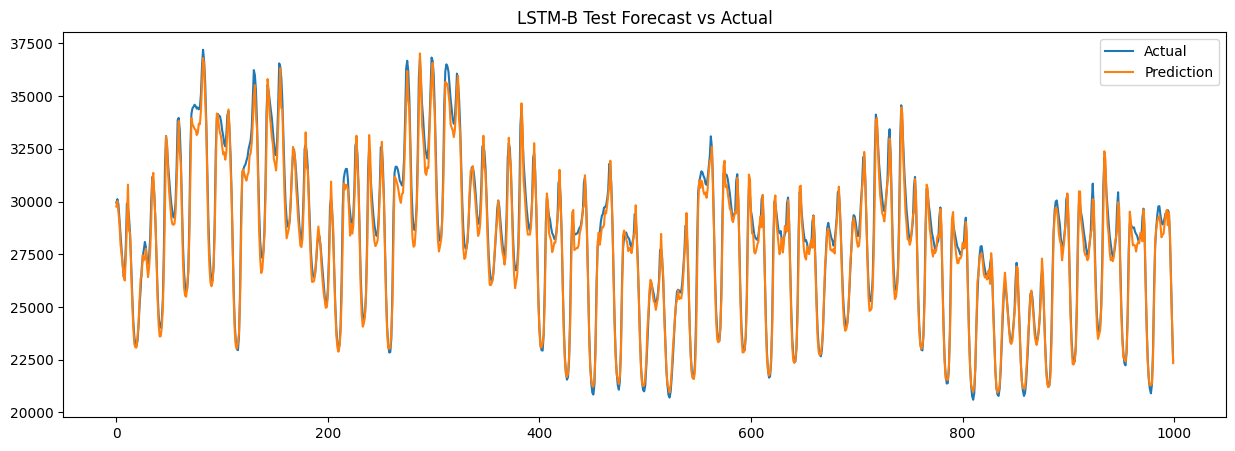

In [154]:
# Plot Forecast vs Actual
plt.figure(figsize=(15,5))

plt.plot(
    y_actual[:1000],
    label="Actual"
)

plt.plot(
    y_pred[:1000],
    label="Prediction"
)

plt.legend()
plt.title("LSTM-B Test Forecast vs Actual")
plt.show()

In [155]:
# Calculate Percentage Improvement Over XGBoost
improvement = (
    (1672.18 - 1278.02) /
    1672.18
) * 100

print(improvement)

23.571625064287343


**Residual / Error Analysis**

In [158]:
residuals = y_actual.flatten() - y_pred.flatten()

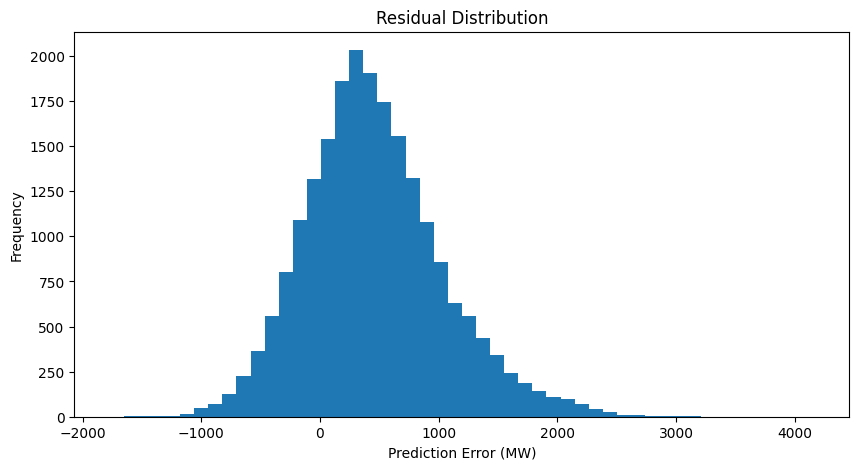

In [159]:
plt.figure(figsize=(10,5))

plt.hist(residuals, bins=50)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error (MW)")
plt.ylabel("Frequency")

plt.show()


**Centered around 0 → good

Mostly negative → overprediction

Mostly positive → underprediction
`**

**Residual Statistics**

In [160]:
print("Mean Error:", residuals.mean())
print("Std Error :", residuals.std())
print("Min Error :", residuals.min())
print("Max Error :", residuals.max())

Mean Error: 455.808374866086
Std Error : 583.5509707098233
Min Error : -1772.0
Max Error : 4164.0


> Residual analysis shows a positive mean residual
(+456 MW).

This indicates a tendency for the model to
underpredict electricity demand.

The model performs very well overall
(Test MAE = 575 MW)
but may underestimate demand during high-load periods.

The LSTM-B model achieved excellent forecasting performance (Test MAE = 575 MW, Test RMSE = 740 MW). Residual analysis revealed a systematic underprediction bias, with a mean residual of +456 MW. The largest observed error was an underprediction of approximately 4164 MW, suggesting reduced accuracy during extreme demand events. Despite this bias, overall predictive performance remained substantially better than all benchmark models tested.

>Mean error close to zero suggests little systematic bias.

**Residuals Over Time**

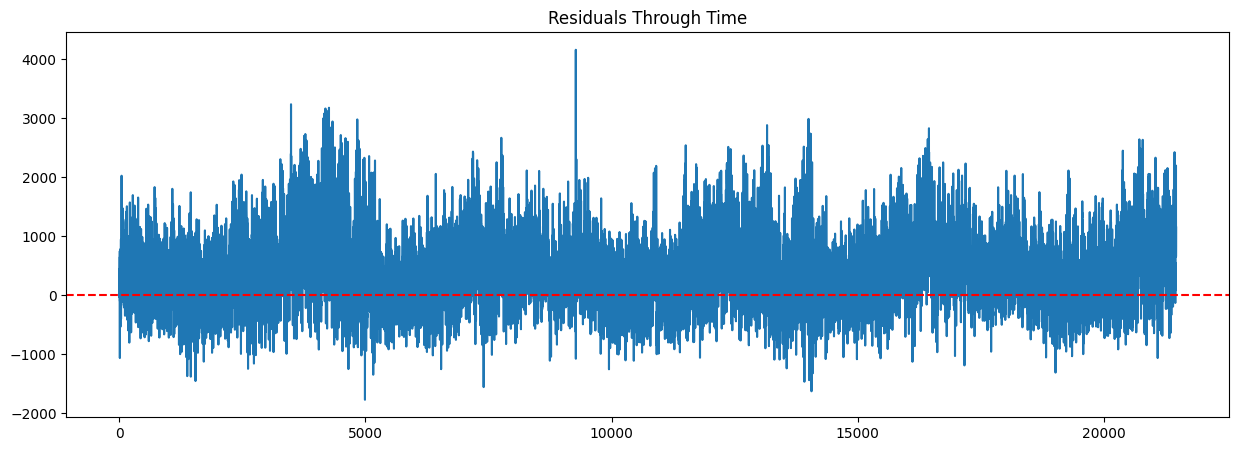

In [161]:
plt.figure(figsize=(15,5))

plt.plot(residuals)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.title("Residuals Through Time")

plt.show()

> Do errors drift?

Do errors cluster?

Are there periods where forecasts consistently fail?

Blue line = prediction error at each test observation.
Red dotted line = perfect prediction (error = 0 MW).
 If a point is +500 on the blue line then model is underpredicting by 500MW . Actual demand = Predicted demand + 500 MW
 If a point is -500 on the blue line then model is overpredicting by 500MW. Predicted demand = Actual demand + 500 MW

We have a systemic underprediction or conservative prediction.
Where there are spikes, the model missed the actual value significantly. This could be during Demand peaks:
Weather events
Holidays
Unusual load conditions

The residuals-through-time analysis showed that prediction errors remained relatively stable throughout the test period, although residuals were predominantly positive. This is consistent with the observed mean residual of +456 MW and indicates a tendency for the model to underpredict electricity demand. Several larger positive residual spikes were observed, suggesting reduced accuracy during high-demand events.

**Actual vs Predicted Scatter**

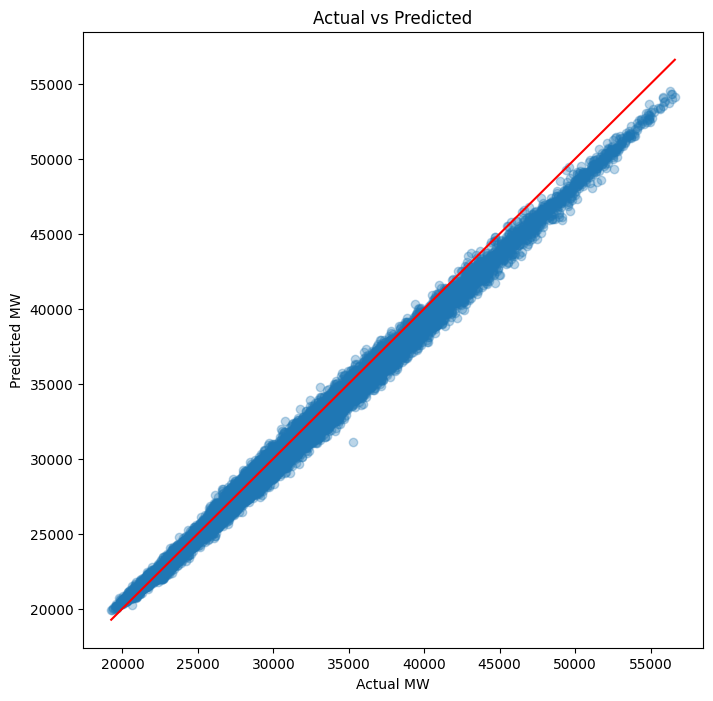

In [162]:
plt.figure(figsize=(8,8))

plt.scatter(
    y_actual,
    y_pred,
    alpha=0.3
)

plt.plot(
    [y_actual.min(), y_actual.max()],
    [y_actual.min(), y_actual.max()],
    color="red"
)

plt.xlabel("Actual MW")
plt.ylabel("Predicted MW")

plt.title("Actual vs Predicted")

plt.show()

> Perfect forecasts lie on the diagonal.
> Points that lie above the red line are overpredictions and those under the red line are underpredictions. As many points lie under the red line over 45000 MW then there is systemic underprediction bias i.e. as the demand rises the model underpredicts. Still the fact that the blue is clustered close to the red line means the model has strong accuracy and good calibration

**Peak-Demand Error Analysis**

In [163]:
peak_threshold = np.percentile(
    y_actual,
    95
)

peak_mask = y_actual.flatten() >= peak_threshold

peak_mae = mean_absolute_error(
    y_actual[peak_mask],
    y_pred[peak_mask]
)

print("Peak-load MAE:", peak_mae)

Peak-load MAE: 1574.5558659217877


> Does the model remain accurate during demand spikes?